# Lab 3 | TV02 - data eda

**Owner: TV02 (điền tên thật).** Trạng thái: REVIEW - EDA hoàn chỉnh trên dữ liệu v1, chờ TV03 review.

Đọc `../docs/TEAM_PLAN.md`, `../docs/DATA_CONTRACT.md` và `../docs/REQUIREMENTS_MAP.md`. Các lệnh setup dưới chỉ đọc dữ liệu và tạo feature chung, chưa fit model trên AEP.

**Dữ liệu dùng chung v1 đã được chuẩn bị ngày 29/10. Thành viên bắt đầu từ 30/10; xem `../docs/DATA_V1.md`.**
**Phạm vi TV02: chỉ EDA, không cần tải/làm sạch dữ liệu hoặc bàn giao dữ liệu ngày 29/10.**

Nguyên tắc EDA trong notebook này:
- Mọi nhận xét về xu hướng/chu kỳ/phân phối tính **trên train** (`Datetime < test_start`); test chỉ dùng để mô tả chung phạm vi/mức (không dùng để chọn feature/tham số).
- Dùng cột `y` gốc (MW) và `observed`; **giữ nguyên NaN** ở 27 giờ thiếu, không điền/không nội suy. Riêng ACF dùng `Series.autocorr`, tự bỏ cặp có NaN.
- Không sửa dữ liệu gốc; hình lưu ở `reports/figures/eda_*.png`, bảng ở `reports/tables/eda_*.csv`.

In [1]:
from pathlib import Path
import json
import sys
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "configs/experiment.json").is_file())
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
from lab3.data import load_prepared, split_supervised
from lab3.features import make_supervised, xy
from lab3.evaluation import regression_metrics
cfg = json.loads((ROOT / "configs/experiment.json").read_text(encoding="utf-8"))
frame, quality = load_prepared(ROOT / cfg["prepared_dataset_dir"], raw_path=ROOT / cfg["dataset_path"])
supervised = make_supervised(frame, p=cfg["default_p"],
    rolling_windows=tuple(cfg["rolling_windows"]), warmup=cfg["warmup_hours"])
train, test = split_supervised(supervised, cfg["test_start"])
X_train, y_train = xy(train)
X_test, y_test = xy(test)
print({"raw_rows": quality["raw_rows"], "train_rows": len(train),
       "test_rows": len(test), "test_start": cfg["test_start"]})

{'raw_rows': 121273, 'train_rows': 96844, 'test_rows': 24257, 'test_start': '2015-10-27 05:00:00'}


## 1. Nguồn, đơn vị và xem trước dữ liệu sẵn có

Nguồn: [AEP Hourly Energy Consumption (Kaggle)](https://www.kaggle.com/datasets/robikscube/hourly-energy-consumption?select=AEP_hourly.csv) - American Electric Power, công suất tiêu thụ trung bình theo giờ, cột `AEP_MW`, đơn vị **MW** (không phải MWh). Dữ liệu v1: `data/interim/AEP_hourly_clean.csv` với 3 cột `Datetime` (giờ địa phương danh nghĩa, không timezone), `y`, `observed`.

In [2]:
import platform
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
FIG = ROOT / "reports/figures"
TAB = ROOT / "reports/tables"
FIG.mkdir(parents=True, exist_ok=True)
TAB.mkdir(parents=True, exist_ok=True)
SAVED = []

def save_fig(fig, name):
    fig.savefig(FIG / name, dpi=120, bbox_inches="tight")
    SAVED.append(f"reports/figures/{name}")

def save_tab(df, name):
    df.to_csv(TAB / name, float_format="%.3f", encoding="utf-8")
    SAVED.append(f"reports/tables/{name}")

# Chuỗi target theo trục giờ danh nghĩa (NaN ở giờ thiếu được giữ nguyên)
cut = pd.Timestamp(cfg["test_start"])
s_all = frame["y"]
s_train = s_all[s_all.index < cut]
s_test = s_all[s_all.index >= cut]

overview = pd.Series({
    "Nguồn": quality["source_url"],
    "Đơn vị": quality["unit"],
    "Từ": quality["start"], "Đến": quality["end"],
    "Dòng CSV gốc": quality["raw_rows"],
    "Timestamp trùng (dòng)": quality["duplicate_timestamp_rows"],
    "Giờ trục danh nghĩa": quality["grid_rows"],
    "Giờ có target": quality["observed_targets"],
    "Giờ thiếu target": quality["missing_nominal_hours"],
    "test_start": cfg["test_start"],
    "Train (giờ / có target)": f"{len(s_train):,} / {s_train.notna().sum():,}",
    "Test (giờ / có target)": f"{len(s_test):,} / {s_test.notna().sum():,}",
}, name="Giá trị")
display(overview.to_frame())
display(frame.head(3))
display(frame.tail(3))

def describe(s):
    d = s.describe().astype(object)
    d["skew"] = s.skew()
    d["kurtosis"] = s.kurt()
    d["CV_%"] = 100 * s.std() / s.mean()
    d["missing"] = int(s.isna().sum())
    d["idxmin"] = s.idxmin()
    d["idxmax"] = s.idxmax()
    return d

stats = pd.DataFrame({"toàn bộ": describe(s_all), "train": describe(s_train),
                      "test": describe(s_test)}).T
save_tab(stats, "eda_descriptive_stats.csv")
print("Thống kê mô tả AEP_MW (MW):")
display(stats)
print(f"Mean test thấp hơn mean train: {100 * (1 - s_test.mean() / s_train.mean()):.2f}%")

,Giá trị
Nguồn,https://www.kaggle.com/datasets/robikscube/hou...
Đơn vị,MW
Từ,2004-10-01 01:00:00
Đến,2018-08-03 00:00:00
Dòng CSV gốc,121273
Timestamp trùng (dòng),4
Giờ trục danh nghĩa,121296
Giờ có target,121269
Giờ thiếu target,27
test_start,2015-10-27 05:00:00


,y,observed
Datetime,,
2004-10-01 01:00:00,"12,379.00",True
2004-10-01 02:00:00,"11,935.00",True
2004-10-01 03:00:00,"11,692.00",True


,y,observed
Datetime,,
2018-08-02 22:00:00,"17,001.00",True
2018-08-02 23:00:00,"15,964.00",True
2018-08-03 00:00:00,"14,809.00",True


Thống kê mô tả AEP_MW (MW):


,count,mean,std,min,25%,50%,75%,max,skew,kurtosis,CV_%,missing,idxmin,idxmax
toàn bộ,"121,269.00","15,499.65","2,591.32","9,581.00","13,630.00","15,310.00","17,200.00","25,695.00",0.38,-0.21,16.72,27,2016-10-02 05:00:00,2008-10-20 14:00:00
train,"97,012.00","15,695.56","2,590.10","9,662.00","13,824.00","15,521.00","17,393.00","25,695.00",0.35,-0.21,16.50,24,2015-05-24 05:00:00,2008-10-20 14:00:00
test,"24,257.00","14,716.17","2,444.04","9,581.00","12,958.00","14,403.00","16,209.00","22,759.00",0.50,-0.13,16.61,3,2016-10-02 05:00:00,2018-01-03 08:00:00


Mean test thấp hơn mean train: 6.24%


**Nhận xét mục 1 (thống kê mô tả):**
- Chuỗi gồm 121.296 giờ danh nghĩa (01/10/2004 01:00 → 03/08/2018 00:00), 121.269 giờ có target; chỉ 27 giờ thiếu (0,02%) nên mất mát dữ liệu không đáng kể.
- Train: trung bình **≈15.696 MW**, độ lệch chuẩn ≈2.590 MW (CV ≈16,5%), trung vị 15.521 MW, khoảng 9.662 → 25.695 MW. Độ lệch (skew ≈0,35) dương nhẹ, kurtosis ≈ −0,21: phân phối gần đối xứng, đuôi phải hơi dài (các giờ cao điểm hè/đông), không có đuôi dày.
- Test có mức trung bình **≈14.716 MW, thấp hơn train ≈6,2%**, độ phân tán tương đương (CV ≈16,6%). Mức test vẫn nằm trong miền giá trị của train nên mô hình cây không bị buộc ngoại suy, nhưng có dịch mức (level shift) cần lưu ý khi đánh giá.
- Giá trị lớn nhất train (25.695 MW, 20/10/2008 14:00) là **một điểm nhảy đơn lẻ**, xem mục 2.

## 2. EDA chuỗi và xu hướng

Vẽ chuỗi toàn kỳ (giờ, trung bình ngày, trung bình trượt 365 ngày), mức trung bình theo năm/tháng và hai mẫu ngắn 2 tuần. Audit thiếu/trùng chỉ **đọc lại** từ `data/interim` (không làm lại pipeline).

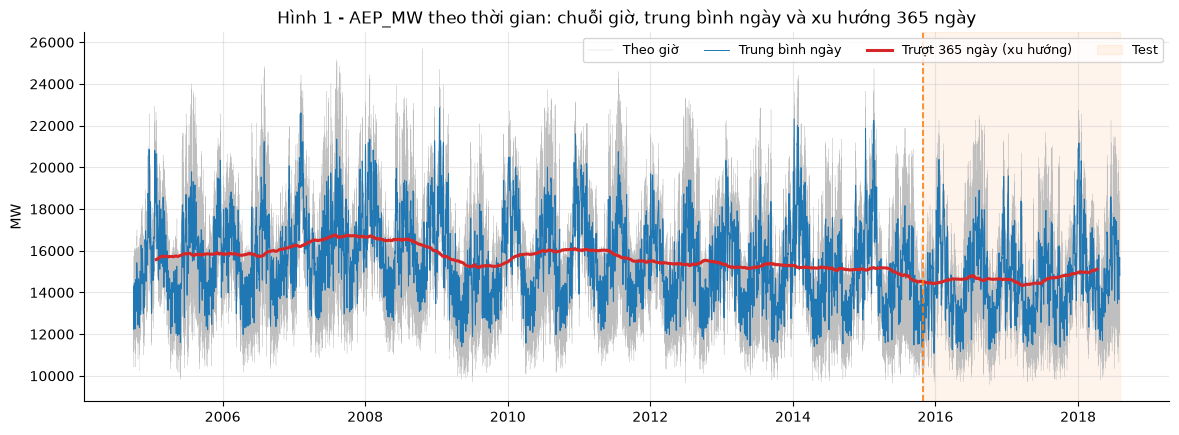

,count,mean,std,min,max,full_year,part
Datetime,,,,,,,
2004,2206,"15,176.72","2,076.67","10,263.00","22,577.00",False,train
2005,8758,"15,842.99","2,570.90","9,823.00","24,015.00",True,train
2006,8758,"15,737.22","2,374.72","10,176.00","24,842.00",True,train
2007,8758,"16,645.52","2,663.61","10,858.00","25,164.00",True,train
2008,8782,"16,536.66","2,507.45","11,021.00","25,695.00",True,train
2009,8758,"15,254.11","2,565.91","9,701.00","24,703.00",True,train
2010,8757,"16,008.62","2,752.39","10,070.00","23,736.00",True,train
2011,8758,"15,815.39","2,485.74","10,479.00","24,597.00",True,train
2012,8781,"15,352.94","2,410.78","9,669.00","23,320.00",True,train


Hồi quy tuyến tính mean năm (năm đủ của train 2005-2014): -107.3 MW/năm
Mean 2005-2008: 16,191 MW | 2011-2014: 15,384 MW


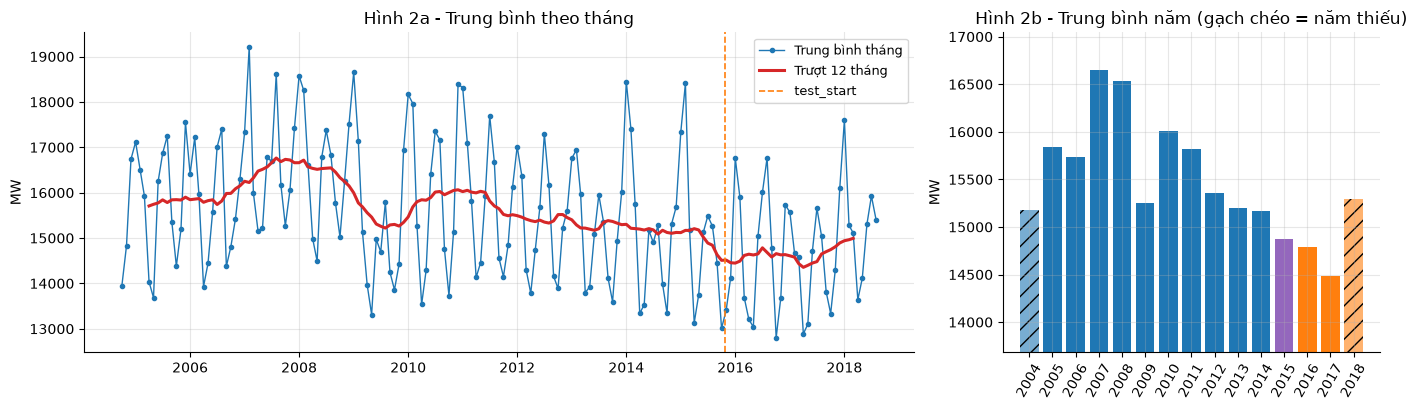

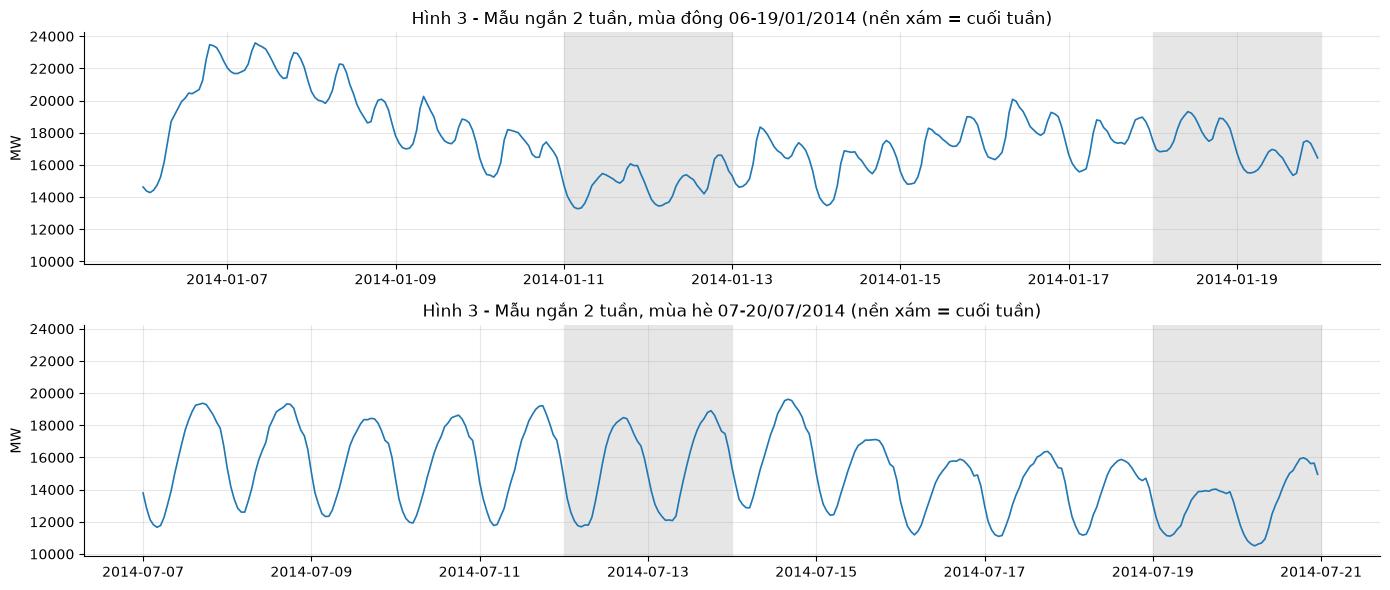

Giờ thiếu theo mẫu:


,số giờ
pattern,
"CN tháng 3/4, 03:00",14
"CN tháng 10/11, 02:00",10
đơn lẻ,3


Giờ thiếu đơn lẻ: ['2010-12-10 00:00', '2012-12-06 04:00', '2014-03-11 14:00']
Timestamp trùng (đã gộp mean trong v1): ['2014-11-02 02:00', '2015-11-01 02:00', '2016-11-06 02:00', '2017-11-05 02:00']
5 giờ lệch mạnh nhất so với median 5 giờ lân cận (train):


,|y - median5|,y
Datetime,,
2008-10-20 14:00:00,"9,342.00","25,695.00"
2008-01-28 08:00:00,"1,065.00","21,873.00"
2011-09-24 13:00:00,"1,003.00","14,732.00"
2009-04-23 22:00:00,998.00,"14,866.00"
2006-04-27 22:00:00,983.00,"15,667.00"


In [3]:
daily = s_all.resample("D").mean()
trend365 = daily.rolling(365, center=True, min_periods=300).mean()

fig, ax = plt.subplots(figsize=(14, 4.8))
ax.plot(s_all.index, s_all.values, lw=0.2, color="0.75", label="Theo giờ")
ax.plot(daily.index, daily.values, lw=0.7, color="tab:blue", label="Trung bình ngày")
ax.plot(trend365.index, trend365.values, lw=2.2, color="tab:red", label="Trượt 365 ngày (xu hướng)")
ax.axvspan(cut, s_all.index[-1], color="tab:orange", alpha=0.08, label="Test")
ax.axvline(cut, color="tab:orange", ls="--", lw=1.2)
ax.set(title="Hình 1 - AEP_MW theo thời gian: chuỗi giờ, trung bình ngày và xu hướng 365 ngày",
       ylabel="MW", xlabel="")
ax.legend(loc="upper right", ncol=4, fontsize=9)
save_fig(fig, "eda_01_series_trend.png"); plt.show()

# Mức theo năm: đánh dấu năm không đủ (2004 bắt đầu tháng 10, 2018 kết thúc tháng 8; 2015 bị cắt bởi test_start)
yearly = s_all.groupby(s_all.index.year).agg(["count", "mean", "std", "min", "max"])
yearly["full_year"] = yearly["count"] >= 8700
yearly["part"] = np.where(yearly.index < cut.year, "train",
                          np.where(yearly.index > cut.year, "test", "train+test"))
save_tab(yearly, "eda_yearly_stats.csv")
display(yearly)

full_train_years = yearly[(yearly["part"] == "train") & yearly["full_year"]]
slope, intercept = np.polyfit(full_train_years.index, full_train_years["mean"], 1)
print(f"Hồi quy tuyến tính mean năm (năm đủ của train {full_train_years.index.min()}-{full_train_years.index.max()}): "
      f"{slope:+.1f} MW/năm")
print(f"Mean 2005-2008: {s_train['2005':'2008'].mean():,.0f} MW | 2011-2014: {s_train['2011':'2014'].mean():,.0f} MW")

monthly = s_all.resample("MS").mean()
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), gridspec_kw={"width_ratios": [2.2, 1]})
axes[0].plot(monthly.index, monthly.values, marker=".", lw=1, label="Trung bình tháng")
axes[0].plot(monthly.index, monthly.rolling(12, center=True).mean(), lw=2.2, color="tab:red",
             label="Trượt 12 tháng")
axes[0].axvline(cut, color="tab:orange", ls="--", lw=1.2, label="test_start")
axes[0].set(title="Hình 2a - Trung bình theo tháng", ylabel="MW")
axes[0].legend(fontsize=9)
colors = ["tab:blue" if p == "train" else "tab:orange" if p == "test" else "tab:purple"
          for p in yearly["part"]]
bars = axes[1].bar(yearly.index.astype(str), yearly["mean"], color=colors)
for bar, full in zip(bars, yearly["full_year"]):
    if not full:
        bar.set_hatch("//"); bar.set_alpha(0.6)
axes[1].set_ylim(yearly["mean"].min() - 800, yearly["mean"].max() + 400)
axes[1].set(title="Hình 2b - Trung bình năm (gạch chéo = năm thiếu)", ylabel="MW")
axes[1].tick_params(axis="x", rotation=60)
fig.tight_layout(); save_fig(fig, "eda_02_monthly_yearly_level.png"); plt.show()

# Hai mẫu ngắn 14 ngày trong train: mùa đông và mùa hè
fig, axes = plt.subplots(2, 1, figsize=(14, 6), sharey=True)
for ax, (a, b, name) in zip(axes, [("2014-01-06", "2014-01-19", "mùa đông 06-19/01/2014"),
                                     ("2014-07-07", "2014-07-20", "mùa hè 07-20/07/2014")]):
    part = s_train[a:b]
    ax.plot(part.index, part.values, lw=1.2)
    for d in pd.date_range(a, b, freq="D"):
        if d.day_of_week >= 5:
            ax.axvspan(d, d + pd.Timedelta(days=1), color="0.9")
    ax.set(title=f"Hình 3 - Mẫu ngắn 2 tuần, {name} (nền xám = cuối tuần)", ylabel="MW")
fig.tight_layout(); save_fig(fig, "eda_03_short_samples.png"); plt.show()

# Audit thiếu/trùng: đọc từ Data v1, không làm lại
missing = pd.read_csv(ROOT / "data/interim/missing_hours.csv", parse_dates=["Datetime"])
dups = pd.read_csv(ROOT / "data/interim/duplicate_timestamps.csv", parse_dates=["Datetime"])
missing["pattern"] = np.select(
    [(missing.Datetime.dt.month.isin([3, 4])) & (missing.Datetime.dt.hour == 3) & (missing.Datetime.dt.day_of_week == 6),
     (missing.Datetime.dt.month.isin([10, 11])) & (missing.Datetime.dt.hour == 2) & (missing.Datetime.dt.day_of_week == 6)],
    ["CN tháng 3/4, 03:00", "CN tháng 10/11, 02:00"], "đơn lẻ")
print("Giờ thiếu theo mẫu:"); display(missing["pattern"].value_counts().to_frame("số giờ"))
print("Giờ thiếu đơn lẻ:", missing.loc[missing.pattern == "đơn lẻ", "Datetime"].dt.strftime("%Y-%m-%d %H:%M").tolist())
print("Timestamp trùng (đã gộp mean trong v1):", sorted(dups["Datetime"].dt.strftime("%Y-%m-%d %H:%M").unique()))

# Kiểm tra điểm nhảy đơn lẻ (chỉ báo cáo, KHÔNG sửa dữ liệu)
resid = s_train - s_train.rolling(5, center=True, min_periods=3).median()
spikes = resid.abs().sort_values(ascending=False).head(5).to_frame("|y - median5|")
spikes["y"] = s_train.loc[spikes.index]
print("5 giờ lệch mạnh nhất so với median 5 giờ lân cận (train):"); display(spikes)

**Nhận xét mục 2 (xu hướng và biến động trên train):**
- **Không có xu hướng tăng dài hạn.** Đường trượt 365 ngày (Hình 1) dao động quanh 15–16,6 nghìn MW: tăng tới đỉnh 2007–2008 (≈16,5–16,6 nghìn MW), giảm rõ năm 2009 (≈15,25 nghìn MW, trùng thời kỳ suy thoái kinh tế - chỉ là bối cảnh, dữ liệu không chứng minh nguyên nhân), hồi phục năm 2010 (≈16,0 nghìn MW) rồi **giảm dần** giai đoạn 2011–2014 (≈15,8 → 15,2 nghìn MW). Hồi quy tuyến tính trên trung bình các năm đủ của train (2005–2014) cho độ dốc **≈ −107 MW/năm** (mean 2005–2008 ≈16.190 MW so với 2011–2014 ≈15.380 MW) - vẫn nhỏ so với độ lệch chuẩn ≈2.590 MW.
- Phần test (2015-10 → 2018-08) tiếp tục mức thấp hơn (Hình 2b), nhất quán với chênh ≈6% ở mục 1. Chuỗi **không dừng về mức trung bình theo thời gian dài** nhưng thay đổi chậm; với dự báo một bước, lag gần (1, 2, 24 giờ) và rolling 24/168 giờ sẽ tự "theo" mức hiện tại.
- **Biến động chủ yếu đến từ mùa vụ chứ không từ xu hướng:** trung bình tháng (Hình 2a) lặp lại mỗi năm hai đỉnh - mùa đông (tháng 1–2) cao nhất và mùa hè (tháng 7–8) - và hai đáy vào tháng 4–5 và tháng 10. Biên độ giữa các tháng (≈3.700 MW) lớn hơn nhiều so với biến thiên giữa các năm.
- **Mẫu ngắn (Hình 3):** dạng chu kỳ ngày rất đều; ngày cuối tuần thấp hơn ngày thường. Mùa đông có 2 đỉnh/ngày (sáng ≈8–9h và tối ≈20h), mùa hè có 1 đỉnh dài buổi chiều. Biên độ trong ngày trung bình ≈4.600 MW.
- **Audit (đọc lại từ v1):** 24/27 giờ thiếu rơi vào Chủ nhật tháng 3/4 lúc 03:00 và Chủ nhật tháng 10/11 lúc 02:00 (2004–2013), 3 giờ thiếu đơn lẻ; 4 timestamp trùng đều ở 02:00 Chủ nhật đầu tháng 11 (2014–2017). Mẫu này **trùng với ngày chuyển giờ mùa hè (DST) ở Mỹ** - gợi ý nguyên nhân là DST, nhưng CSV không có timezone nên không khẳng định; v1 dùng trục giờ danh nghĩa và gộp trùng bằng mean.
- **Điểm bất thường:** 20/10/2008 14:00 = 25.695 MW trong khi hai giờ kề là ≈16.350 và ≈15.990 MW (lệch ≈9.300 MW) - gần như chắc chắn là lỗi ghi nhận một giờ. Không sửa dữ liệu (đúng hợp đồng); báo TV03/TV04 lưu ý vì điểm này nằm trong train, có thể ảnh hưởng nhẹ tới lag/rolling quanh thời điểm đó.

## 3. EDA chu kỳ theo giờ, ngày và tuần

Khảo sát trên **train**, dùng cột `y` có quan sát (`observed=True`), giữ nguyên missing target. Mùa: Đông = 12–2, Xuân = 3–5, Hè = 6–8, Thu = 9–11.

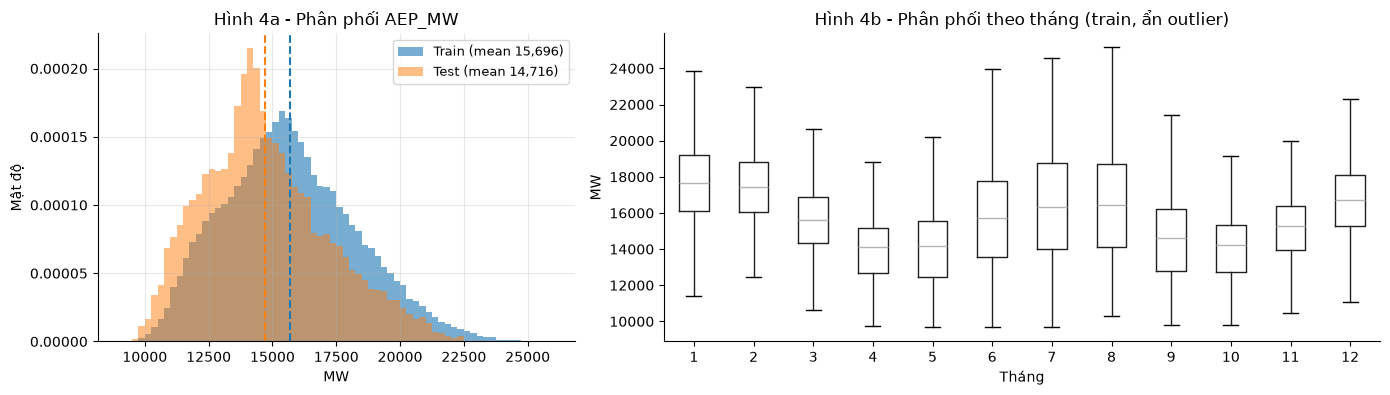

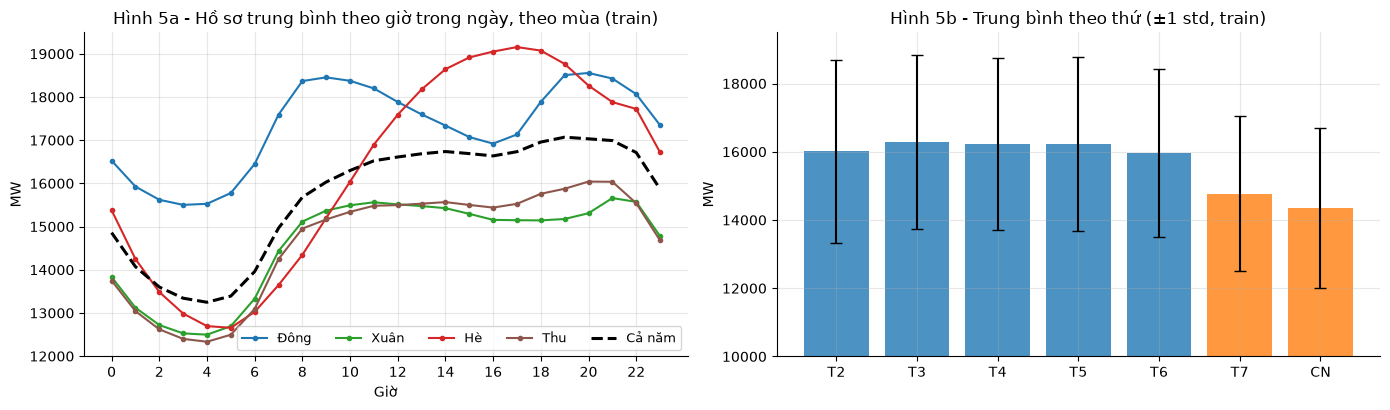

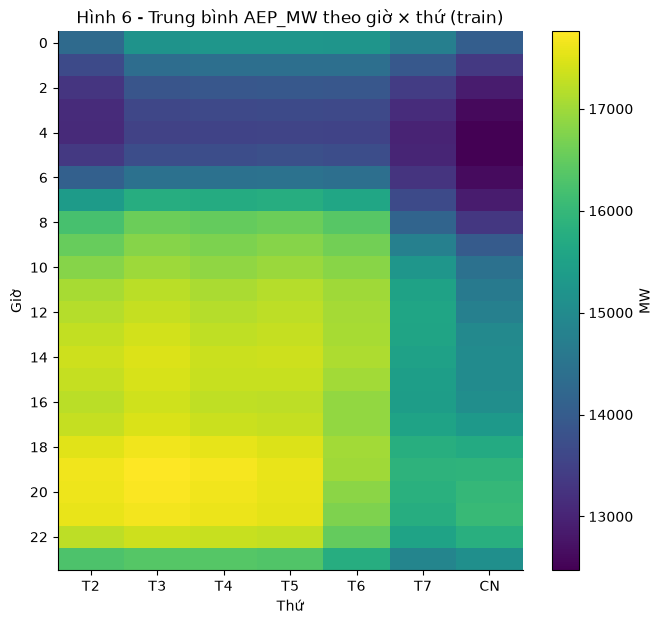

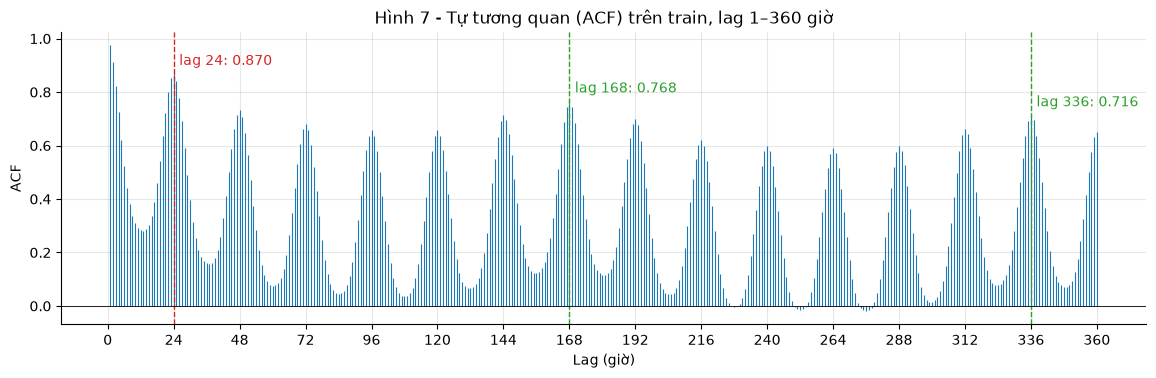

,Kết quả
Giờ thấp nhất (cả năm),"4h - 13,247 MW"
Giờ cao nhất (cả năm),"19h - 17,069 MW"
Tỉ lệ cao/thấp theo giờ,1.288
Đỉnh mùa Đông,"20h - 18,556 MW"
Đỉnh mùa Hè,"17h - 19,156 MW"
Mean ngày thường (T2–T6),"16,148 MW"
Mean cuối tuần (T7–CN),"14,565 MW"
Cuối tuần so với ngày thường,-9.8%
Tháng cao nhất / thấp nhất,1 / 4


,mean,std,min,max
season,,,,
Đông,"17,293.64","2,147.13","10,903.00","24,739.00"
Xuân,"14,598.16","2,018.12","9,662.00","22,556.00"
Hè,"16,273.29","2,963.14","9,669.00","25,164.00"
Thu,"14,663.35","2,059.90","9,801.00","25,695.00"


,1,2,3,6,12,24,48,72,144,168,336,8760
ACF,0.98,0.91,0.82,0.52,0.28,0.87,0.73,0.68,0.72,0.77,0.72,0.68


In [4]:
tr = frame.loc[frame.index < cut]
tr = tr.loc[tr["observed"], "y"]           # chỉ giờ có quan sát; không điền NaN
SEASON = {12: "Đông", 1: "Đông", 2: "Đông", 3: "Xuân", 4: "Xuân", 5: "Xuân",
          6: "Hè", 7: "Hè", 8: "Hè", 9: "Thu", 10: "Thu", 11: "Thu"}
DOW = ["T2", "T3", "T4", "T5", "T6", "T7", "CN"]
cal = pd.DataFrame({"y": tr, "hour": tr.index.hour, "dow": tr.index.day_of_week,
                    "month": tr.index.month, "season": tr.index.month.map(SEASON)})

# --- Phân phối: histogram train vs test + boxplot theo tháng
te = s_test.dropna()
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), gridspec_kw={"width_ratios": [1, 1.5]})
bins = np.linspace(9000, 26000, 69)
axes[0].hist(tr, bins=bins, density=True, alpha=0.6, label=f"Train (mean {tr.mean():,.0f})")
axes[0].hist(te, bins=bins, density=True, alpha=0.5, label=f"Test (mean {te.mean():,.0f})")
axes[0].axvline(tr.mean(), color="tab:blue", ls="--"); axes[0].axvline(te.mean(), color="tab:orange", ls="--")
axes[0].set(title="Hình 4a - Phân phối AEP_MW", xlabel="MW", ylabel="Mật độ"); axes[0].legend(fontsize=9)
cal.boxplot(column="y", by="month", ax=axes[1], showfliers=False, grid=False)
axes[1].set(title="Hình 4b - Phân phối theo tháng (train, ẩn outlier)", xlabel="Tháng", ylabel="MW")
fig.suptitle(""); fig.tight_layout(); save_fig(fig, "eda_04_distribution.png"); plt.show()

# --- Hồ sơ theo giờ theo mùa, và theo thứ trong tuần
hour_season = cal.pivot_table(index="hour", columns="season", values="y", aggfunc="mean")[["Đông", "Xuân", "Hè", "Thu"]]
hour_all = cal.groupby("hour")["y"].mean()
dow_stats = cal.groupby("dow")["y"].agg(["mean", "std"]).set_axis(DOW)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for col, c in zip(hour_season, ["tab:blue", "tab:green", "tab:red", "tab:brown"]):
    axes[0].plot(hour_season.index, hour_season[col], marker=".", color=c, label=col)
axes[0].plot(hour_all.index, hour_all, color="k", lw=2.2, ls="--", label="Cả năm")
axes[0].set(title="Hình 5a - Hồ sơ trung bình theo giờ trong ngày, theo mùa (train)",
            xlabel="Giờ", ylabel="MW", xticks=range(0, 24, 2)); axes[0].legend(fontsize=9, ncol=5)
axes[1].bar(dow_stats.index, dow_stats["mean"], yerr=dow_stats["std"], capsize=4,
            color=["tab:blue"] * 5 + ["tab:orange"] * 2, alpha=0.8)
axes[1].set_ylim(10000, 19500)
axes[1].set(title="Hình 5b - Trung bình theo thứ (±1 std, train)", ylabel="MW")
fig.tight_layout(); save_fig(fig, "eda_05_hour_dow_profile.png"); plt.show()
save_tab(hour_season.assign(ca_nam=hour_all), "eda_hourly_profile_by_season.csv")

# --- Heatmap giờ x thứ
heat = cal.pivot_table(index="hour", columns="dow", values="y", aggfunc="mean").set_axis(DOW, axis=1)
fig, ax = plt.subplots(figsize=(7.5, 7))
im = ax.imshow(heat.values, aspect="auto", cmap="viridis")
ax.set(xticks=range(7), xticklabels=DOW, yticks=range(0, 24, 2), yticklabels=range(0, 24, 2),
       xlabel="Thứ", ylabel="Giờ", title="Hình 6 - Trung bình AEP_MW theo giờ × thứ (train)")
ax.grid(False); fig.colorbar(im, ax=ax, label="MW")
save_fig(fig, "eda_06_heatmap_hour_dow.png"); plt.show()

# --- ACF: Series.autocorr bỏ cặp chứa NaN, không điền target
lags = np.arange(1, 24 * 15 + 1)
acf = pd.Series([s_train.autocorr(int(k)) for k in lags], index=lags)
key_lags = [1, 2, 3, 6, 12, 24, 48, 72, 144, 168, 336, 8760]
acf_key = pd.Series({k: s_train.autocorr(k) for k in key_lags}, name="ACF")
fig, ax = plt.subplots(figsize=(14, 3.8))
ax.vlines(acf.index, 0, acf.values, lw=0.8)
for k, c in [(24, "tab:red"), (168, "tab:green"), (336, "tab:green")]:
    ax.axvline(k, color=c, ls="--", lw=1)
    ax.annotate(f"lag {k}: {acf[k]:.3f}", (k, acf[k]), xytext=(4, 6), textcoords="offset points", color=c)
ax.axhline(0, color="k", lw=0.6)
ax.set(title="Hình 7 - Tự tương quan (ACF) trên train, lag 1–360 giờ", xlabel="Lag (giờ)", ylabel="ACF",
       xticks=range(0, 361, 24))
save_fig(fig, "eda_07_acf.png"); plt.show()

profile = pd.Series({
    "Giờ thấp nhất (cả năm)": f"{hour_all.idxmin()}h - {hour_all.min():,.0f} MW",
    "Giờ cao nhất (cả năm)": f"{hour_all.idxmax()}h - {hour_all.max():,.0f} MW",
    "Tỉ lệ cao/thấp theo giờ": f"{hour_all.max() / hour_all.min():.3f}",
    "Đỉnh mùa Đông": f"{hour_season['Đông'].idxmax()}h - {hour_season['Đông'].max():,.0f} MW",
    "Đỉnh mùa Hè": f"{hour_season['Hè'].idxmax()}h - {hour_season['Hè'].max():,.0f} MW",
    "Mean ngày thường (T2–T6)": f"{cal.loc[cal.dow < 5, 'y'].mean():,.0f} MW",
    "Mean cuối tuần (T7–CN)": f"{cal.loc[cal.dow >= 5, 'y'].mean():,.0f} MW",
    "Cuối tuần so với ngày thường": f"{100 * (cal.loc[cal.dow >= 5, 'y'].mean() / cal.loc[cal.dow < 5, 'y'].mean() - 1):+.1f}%",
    "Tháng cao nhất / thấp nhất": f"{cal.groupby('month')['y'].mean().idxmax()} / {cal.groupby('month')['y'].mean().idxmin()}",
}, name="Kết quả")
display(profile.to_frame())
display(cal.groupby("season")["y"].agg(["mean", "std", "min", "max"]).loc[["Đông", "Xuân", "Hè", "Thu"]])
display(acf_key.to_frame().T)
save_tab(acf_key.to_frame(), "eda_acf_key_lags.csv")

**Nhận xét mục 3 (phân phối và chu kỳ trên train):**
- **Phân phối (Hình 4a):** một đỉnh, hơi lệch phải; phân phối test dịch sang trái so với train (khớp chênh mức ≈6%). Boxplot theo tháng (Hình 4b) cho thấy **mùa vụ năm dạng hai đỉnh**: tháng 1–2 cao nhất (≈17,5–17,6 nghìn MW, sưởi ấm), tháng 7–8 là đỉnh phụ (≈16,5 nghìn MW, điều hòa), tháng 4 và 10 thấp nhất (≈14,0 nghìn MW). Mùa Hè có độ phân tán lớn nhất (std ≈2.960 MW so với ≈2.150 MW mùa Đông) do biên độ trong ngày rất lớn.
- **Chu kỳ ngày (Hình 5a, 6):** thấp nhất lúc **4h (≈13.250 MW)**, cao nhất khoảng **19h (≈17.070 MW)**, chênh ≈29%. Dạng hồ sơ phụ thuộc mùa: mùa Đông có hai đỉnh (sáng ≈9h ≈18.460 MW và tối ≈20h ≈18.560 MW), mùa Hè có một đỉnh buổi chiều ≈17h và đạt mức giờ cao nhất trong các mùa (≈19.150 MW) - tức là có **tương tác giờ × mùa**.
- **Chu kỳ tuần (Hình 5b, 6):** T2–T6 gần như bằng nhau (≈16,0–16,3 nghìn MW); T7 và CN thấp hơn rõ (≈14,8 và ≈14,4 nghìn MW). Trung bình cuối tuần thấp hơn ngày thường ≈10%, chênh lệch rõ nhất ở khung giờ sáng/ban ngày (Hình 6).
- **ACF (Hình 7):** lag 1 ≈0,975 và lag 2 ≈0,91 - quán tính rất mạnh; ACF giảm tới cực tiểu quanh lag 12 (≈0,29) rồi tăng lại ở **lag 24 (≈0,87)**, lặp lại mỗi 24 giờ; **lag 168 (≈0,77) cao hơn lag 48–144**, xác nhận chu kỳ tuần. Lag 8760 (≈0,68) phản ánh mùa vụ năm. ACF giảm rất chậm, nhất quán với chuỗi có thành phần mùa mạnh và mức thay đổi chậm.

## 4. Nhận xét từ các biểu đồ

Bảng tổng hợp các con số chính (tính lại trong ô dưới) và nhận xét chung; giả định giờ danh nghĩa trích từ `docs/DATA_V1.md`.

In [5]:
findings = pd.DataFrame([
    ("Mức & phân tán", "Mean / std train (MW)", f"{s_train.mean():,.0f} / {s_train.std():,.0f}"),
    ("Mức & phân tán", "Mean test so với train", f"{100 * (s_test.mean() / s_train.mean() - 1):+.1f}%"),
    ("Xu hướng", "Độ dốc mean năm đủ (train)", f"{slope:+.1f} MW/năm"),
    ("Chu kỳ ngày", "Giờ thấp / cao nhất", f"{hour_all.idxmin()}h / {hour_all.idxmax()}h"),
    ("Chu kỳ ngày", "Biên độ trung bình trong ngày", f"{(s_train.resample('D').max() - s_train.resample('D').min()).mean():,.0f} MW"),
    ("Chu kỳ tuần", "Cuối tuần so với ngày thường", profile["Cuối tuần so với ngày thường"]),
    ("Mùa vụ năm", "Tháng cao nhất / thấp nhất", profile["Tháng cao nhất / thấp nhất"]),
    ("Tự tương quan", "ACF lag 1 / 24 / 168", f"{acf_key[1]:.3f} / {acf_key[24]:.3f} / {acf_key[168]:.3f}"),
    ("Chất lượng", "Giờ thiếu / timestamp trùng", f"{quality['missing_nominal_hours']} / {quality['duplicate_timestamp_rows']}"),
    ("Chất lượng", "Điểm nhảy lớn nhất (train)", f"{spikes.index[0]} ({spikes['y'].iloc[0]:,.0f} MW)"),
], columns=["Nhóm", "Chỉ số", "Giá trị"])
save_tab(findings.set_index(["Nhóm", "Chỉ số"]), "eda_key_findings.csv")
display(findings)

,Nhóm,Chỉ số,Giá trị
0,Mức & phân tán,Mean / std train (MW),"15,696 / 2,590"
1,Mức & phân tán,Mean test so với train,-6.2%
2,Xu hướng,Độ dốc mean năm đủ (train),-107.3 MW/năm
3,Chu kỳ ngày,Giờ thấp / cao nhất,4h / 19h
4,Chu kỳ ngày,Biên độ trung bình trong ngày,"4,629 MW"
5,Chu kỳ tuần,Cuối tuần so với ngày thường,-9.8%
6,Mùa vụ năm,Tháng cao nhất / thấp nhất,1 / 4
7,Tự tương quan,ACF lag 1 / 24 / 168,0.975 / 0.870 / 0.768
8,Chất lượng,Giờ thiếu / timestamp trùng,27 / 4
9,Chất lượng,Điểm nhảy lớn nhất (train),"2008-10-20 14:00:00 (25,695 MW)"


**Nhận xét tổng hợp:**
1. **Ba chu kỳ chồng nhau là đặc trưng chính của AEP_MW:** ngày (24h, mạnh nhất), tuần (168h, do ngày làm việc/cuối tuần) và năm (hai đỉnh đông–hè). Xu hướng dài hạn yếu, chỉ là mức thay đổi chậm (đỉnh 2007–2008, giảm 2009, giảm nhẹ sau 2011); mức test thấp hơn train ≈6%.
2. **Hàm ý cho features (gửi TV03/TV04):** lag 1–2 và lag 24 mang nhiều thông tin nhất; lag 168 có giá trị riêng (ACF lag 168 > lag 48–144), nên đáng thử p = 168 trong khảo sát p trên CV, cũng như rolling 24/168 đã có trong config. Biến lịch (giờ, thứ, tháng/mùa, cờ cuối tuần) có thể hữu ích vì hồ sơ giờ khác theo mùa - đây là gợi ý, quyết định cuối vẫn phải theo CV trên train.
3. **Hàm ý cho đánh giá (TV05/TV06):** baseline seasonal-naive lag 24 và lag 168 là đối chứng mạnh do ACF cao; vì mức test thấp hơn, cần so sánh trên cùng index test và chú ý MAPE tăng khi mức thấp. Mùa Hè có phân tán lớn nhất (và mùa Đông có mức cao nhất) nên sai số tuyệt đối có thể cao hơn ở các tháng này.
4. **Giới hạn dữ liệu / giả định:** `Datetime` là **giờ địa phương danh nghĩa, không timezone**; 24/27 giờ thiếu và cả 4 timestamp trùng nằm đúng các Chủ nhật chuyển giờ (DST) nhưng v1 **không khẳng định đã khôi phục DST hay đổi sang UTC**. Trùng được gộp bằng mean (mất phân biệt hai quan sát); giờ thiếu giữ `NaN`, không dùng để fit/chấm. Điểm nhảy 20/10/2008 14:00 được giữ nguyên, chỉ ghi nhận.

## 5. Handoff EDA

Thông tin tái tạo: input + hash, phiên bản thư viện, danh sách output. Lệnh tái tạo từ kernel mới (thư mục gốc Lab3):
`.\.venv\Scripts\python.exe -m jupyter nbconvert --to notebook --execute --inplace notebooks/01_data_eda.ipynb` (hoặc Restart Kernel → Run All). TV03 dùng dữ liệu v1 độc lập, không cần chờ EDA.

In [6]:
manifest = json.loads((ROOT / cfg["prepared_dataset_dir"] / "manifest.json").read_text(encoding="utf-8"))
handoff = {
    "input": [cfg["dataset_path"], cfg["prepared_dataset_dir"] + "/AEP_hourly_clean.csv"],
    "raw_sha256": manifest["raw_sha256"],
    "clean_sha256": manifest["files"]["AEP_hourly_clean.csv"],
    "test_start": cfg["test_start"],
    "versions": {"python": platform.python_version(), "numpy": np.__version__,
                 "pandas": pd.__version__, "matplotlib": matplotlib.__version__},
    "outputs": SAVED,
}
print(json.dumps(handoff, ensure_ascii=False, indent=2))
assert all((ROOT / p).is_file() for p in SAVED), "Thiếu file output"
print(f"OK: {len(SAVED)} output đã lưu.")

{
  "input": [
    "data/raw/AEP_hourly.csv",
    "data/interim/AEP_hourly_clean.csv"
  ],
  "raw_sha256": "109d122f7b485555c609eecdec2cd5a03172e0a08acd358d863acc93eb452585",
  "clean_sha256": "7682ea773d7aed2893c55793767555c3a2d098d8aa9bcb69e0c4df1b09aa476e",
  "test_start": "2015-10-27 05:00:00",
  "versions": {
    "python": "3.12.10",
    "numpy": "2.5.4",
    "pandas": "3.1.0",
    "matplotlib": "3.11.2"
  },
  "outputs": [
    "reports/tables/eda_descriptive_stats.csv",
    "reports/figures/eda_01_series_trend.png",
    "reports/tables/eda_yearly_stats.csv",
    "reports/figures/eda_02_monthly_yearly_level.png",
    "reports/figures/eda_03_short_samples.png",
    "reports/figures/eda_04_distribution.png",
    "reports/figures/eda_05_hour_dow_profile.png",
    "reports/tables/eda_hourly_profile_by_season.csv",
    "reports/figures/eda_06_heatmap_hour_dow.png",
    "reports/figures/eda_07_acf.png",
    "reports/tables/eda_acf_key_lags.csv",
    "reports/tables/eda_key_findings.csv"

## Trước khi bàn giao
- Restart Kernel -> Run All.
- Ghi config/data hash/lệnh chạy/output.
- Hoàn thiện `../docs/handoffs/TV02.md`.
- Nhờ reviewer theo TEAM_PLAN; không coi setup chạy được là bài đã xong.